# Snap2JSON analysis: charts

Every number comes from the saved results (`results/tables/*.json`, `results/runs/*.jsonl`); nothing is retyped.
Run from the repo root or from `eval/`:
`.venv/bin/jupyter nbconvert --to notebook --execute --inplace eval/analysis.ipynb`.
Charts are saved to `results/charts/`. Write-up: `results/REPORT.md`.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "results").exists() else Path.cwd().parent
sys.path[:0] = [str(ROOT / "src"), str(ROOT)]
from eval.metrics import _same  # noqa: E402

TABLES, RUNS, CHARTS = ROOT / "results" / "tables", ROOT / "results" / "runs", ROOT / "results" / "charts"
CHARTS.mkdir(parents=True, exist_ok=True)
SIZES = ["2B", "4B", "8B"]
METHODS = {"ocr_llm": "OCR+LLM (plain)", "ocr_llm_rows": "OCR+LLM (rows, A)", "vlm": "VLM (image)"}
COLORS = {"ocr_llm": "#9aa5b1", "ocr_llm_rows": "#4c78a8", "vlm": "#e45756", "ocr_llm_rows-ocrT": "#72b7b2"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.axisbelow": True})


def table(method, size, split):
    p = TABLES / f"{method}__Qwen_Qwen3-VL-{size}-Instruct__{split}.json"
    return json.loads(p.read_text(encoding="utf-8")) if p.exists() else None


def e2e(t):
    return t.get("mean_end_to_end_seconds") or t["mean_seconds"]


def save(fig, name):
    fig.tight_layout()
    fig.savefig(CHARTS / f"{name}.png", bbox_inches="tight")
    plt.show()

## 1. Image vs text, by model size (test)

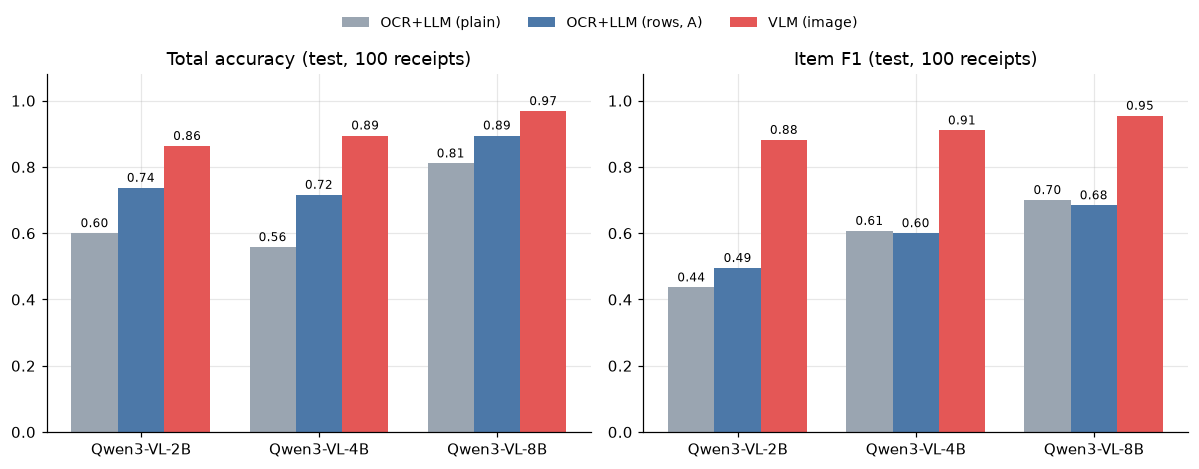

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
w = 0.26
for ax, metric, title in [(axes[0], "total_acc", "Total accuracy"), (axes[1], "items_f1", "Item F1")]:
    for k, m in enumerate(METHODS):
        vals = [table(m, s, "test")[metric] for s in SIZES]
        bars = ax.bar([i + (k - 1) * w for i in range(3)], vals, w, label=METHODS[m], color=COLORS[m])
        ax.bar_label(bars, fmt="%.2f", fontsize=8, padding=2)
    ax.set_xticks(range(3), [f"Qwen3-VL-{s}" for s in SIZES])
    ax.set_ylim(0, 1.08)
    ax.set_title(f"{title} (test, 100 receipts)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=4, fontsize=9, bbox_to_anchor=(0.5, 1.07), frameon=False)
save(fig, "1_image_vs_text_test")

## 2. Accuracy vs speed (test, end to end on the lab machine; OCR on CPU)

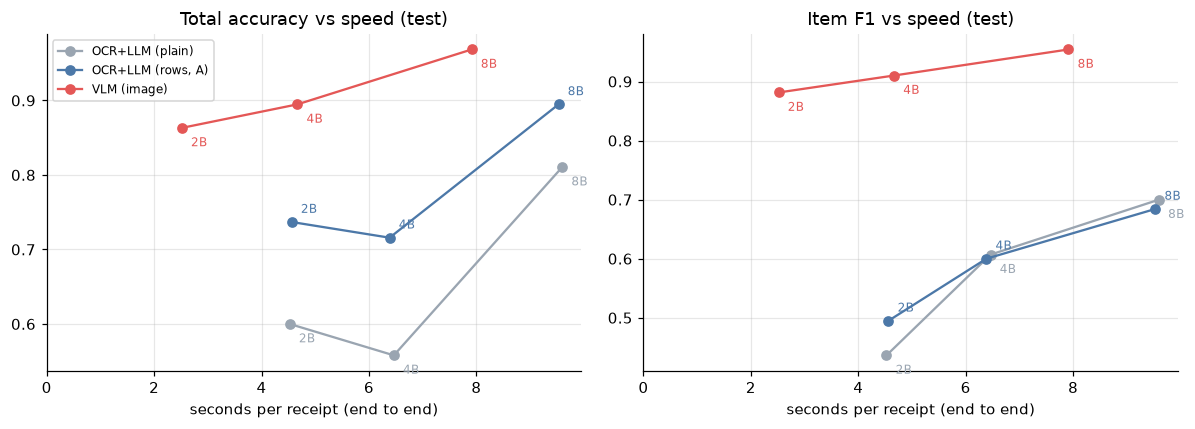

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric, title in [(axes[0], "total_acc", "Total accuracy"), (axes[1], "items_f1", "Item F1")]:
    for m in METHODS:
        xs = [e2e(table(m, s, "test")) for s in SIZES]
        ys = [table(m, s, "test")[metric] for s in SIZES]
        ax.plot(xs, ys, "o-", color=COLORS[m], label=METHODS[m])
        for x, y, s in zip(xs, ys, SIZES):
            ax.annotate(s, (x, y), textcoords="offset points", xytext=(6, 6) if m == "ocr_llm_rows" else (6, -12), fontsize=8, color=COLORS[m])
    ax.set_xlabel("seconds per receipt (end to end)")
    ax.set_title(f"{title} vs speed (test)")
    ax.set_xlim(0, None)
axes[0].legend(fontsize=8)
save(fig, "2_accuracy_vs_speed_test")

## 3. Degraded photos: total accuracy by effect (test_degraded)

Computed from the saved per-receipt outputs with the same scorer as the tables. 22–25 scored receipts per effect,
so differences of 1–3 receipts are noise.

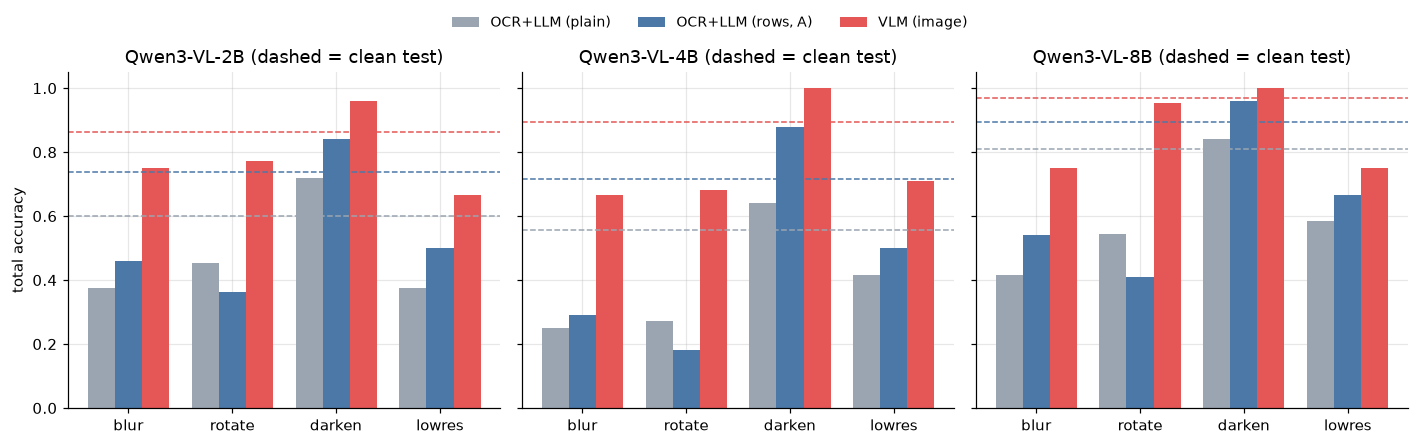

In [4]:
gt = {r["id"]: r for r in map(json.loads, open(ROOT / "data" / "processed" / "test_degraded.jsonl", encoding="utf-8"))}
EFFECTS = ["blur", "rotate", "darken", "lowres"]


def by_effect(method, size):
    ok, n = dict.fromkeys(EFFECTS, 0), dict.fromkeys(EFFECTS, 0)
    for o in map(json.loads, open(RUNS / f"{method}__Qwen_Qwen3-VL-{size}-Instruct__test_degraded.jsonl",
                                  encoding="utf-8")):
        g = gt[o["receipt_id"]]
        if g["receipt"]["total"] is None:
            continue
        e = g["degradation"]
        n[e] += 1
        ok[e] += bool(_same("total", (o["receipt"] or {}).get("total"), g["receipt"]["total"]))
    return [ok[e] / n[e] for e in EFFECTS]


clean = {(m, s): table(m, s, "test")["total_acc"] for m in METHODS for s in SIZES}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
w = 0.26
for ax, s in zip(axes, SIZES):
    for k, m in enumerate(METHODS):
        ax.bar([i + (k - 1) * w for i in range(4)], by_effect(m, s), w, label=METHODS[m], color=COLORS[m])
        ax.axhline(clean[(m, s)], color=COLORS[m], ls="--", lw=1)
    ax.set_xticks(range(4), EFFECTS)
    ax.set_title(f"Qwen3-VL-{s} (dashed = clean test)")
    ax.set_ylim(0, 1.05)
axes[0].set_ylabel("total accuracy")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=4, fontsize=9, bbox_to_anchor=(0.5, 1.07), frameon=False)
save(fig, "3_degraded_by_effect")

## 4. How far do text fixes get? (validation)

Plain OCR text -> rows (Method A) -> rows with the larger OCR detector (T, REPORT.md 6.10), against the image method.
T was run on validation only, for 2B and 8B.

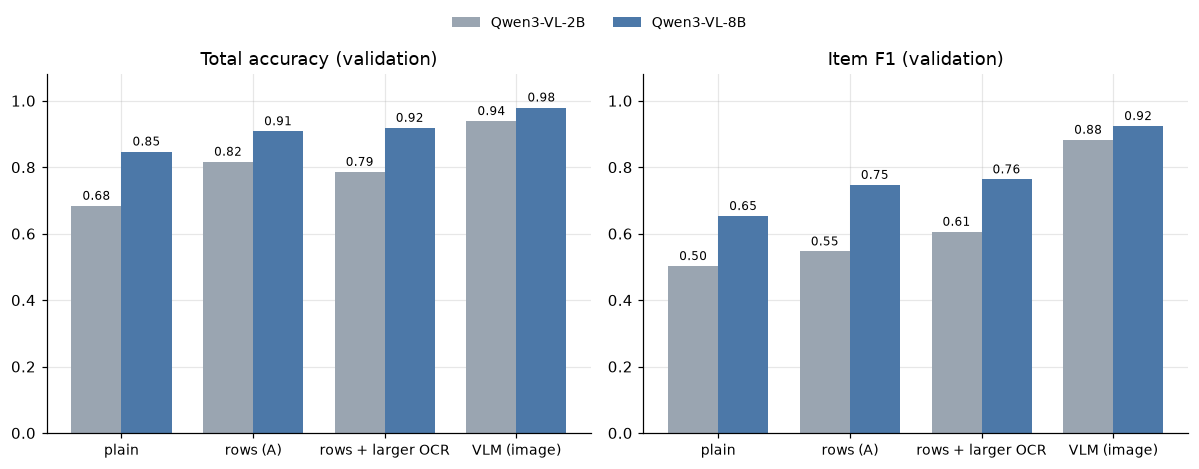

In [5]:
steps = [("ocr_llm", "plain"), ("ocr_llm_rows", "rows (A)"), ("ocr_llm_rows-ocrT", "rows + larger OCR"),
         ("vlm", "VLM (image)")]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric, title in [(axes[0], "total_acc", "Total accuracy"), (axes[1], "items_f1", "Item F1")]:
    for k, s in enumerate(["2B", "8B"]):
        vals = [table(m, s, "validation")[metric] for m, _ in steps]
        bars = ax.bar([i + (k - 0.5) * 0.38 for i in range(4)], vals, 0.38, label=f"Qwen3-VL-{s}",
                      color=["#9aa5b1", "#4c78a8"][k])
        ax.bar_label(bars, fmt="%.2f", fontsize=8, padding=2)
    ax.set_xticks(range(4), [lbl for _, lbl in steps], fontsize=9)
    ax.set_ylim(0, 1.08)
    ax.set_title(f"{title} (validation)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=4, fontsize=9, bbox_to_anchor=(0.5, 1.07), frameon=False)
save(fig, "4_text_fixes_validation")

## 5. OCR accuracy by field (`eval/ocr_accuracy.py`, REPORT.md 6.11)

Labelled CORD words only; rotated degraded receipts are not scored.

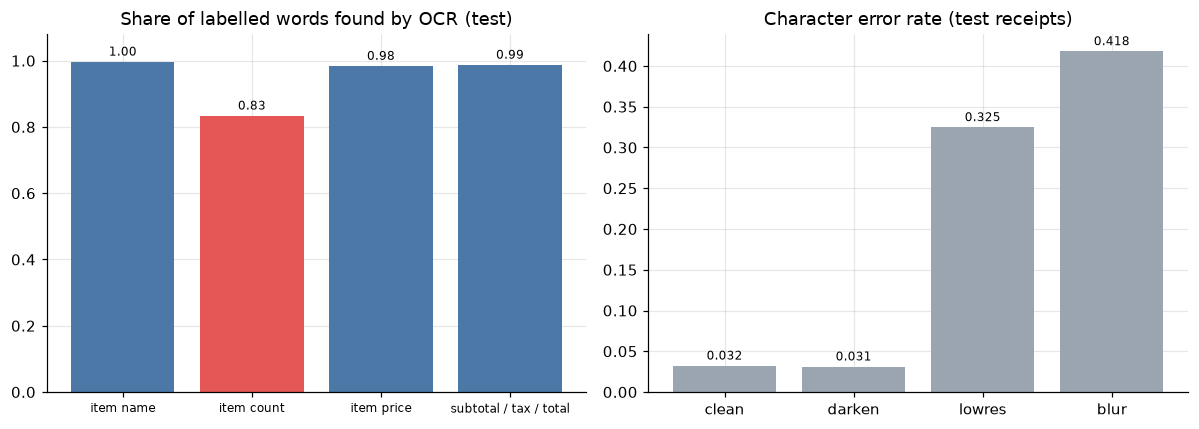

In [6]:
acc = json.loads((TABLES / "ocr_accuracy.json").read_text(encoding="utf-8"))
fields = ["item name", "item count", "item price", "subtotal / tax / total"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
t = acc["test"]
vals = [t[f]["detected"] for f in fields]
bars = axes[0].bar(fields, vals, color=["#4c78a8", "#e45756", "#4c78a8", "#4c78a8"])
axes[0].bar_label(bars, fmt="%.2f", fontsize=8, padding=2)
axes[0].set_ylim(0, 1.08)
axes[0].set_title("Share of labelled words found by OCR (test)")
axes[0].tick_params(axis="x", labelsize=8)
splits = ["test", "test_degraded/darken", "test_degraded/lowres", "test_degraded/blur"]
cer = [acc[s]["all"]["cer"] for s in splits]
bars = axes[1].bar(["clean", "darken", "lowres", "blur"], cer, color="#9aa5b1")
axes[1].bar_label(bars, fmt="%.3f", fontsize=8, padding=2)
axes[1].set_title("Character error rate (test receipts)")
save(fig, "5_ocr_accuracy")

## 6. Why 4B is below 2B on text totals (REPORT.md 6.9)

Wrong totals that are exactly 1000x too small (e.g. `"total": 60.000`, which JSON reads as 60). Counted by
`eval/thousands_check.py`; recomputed here from the runs.

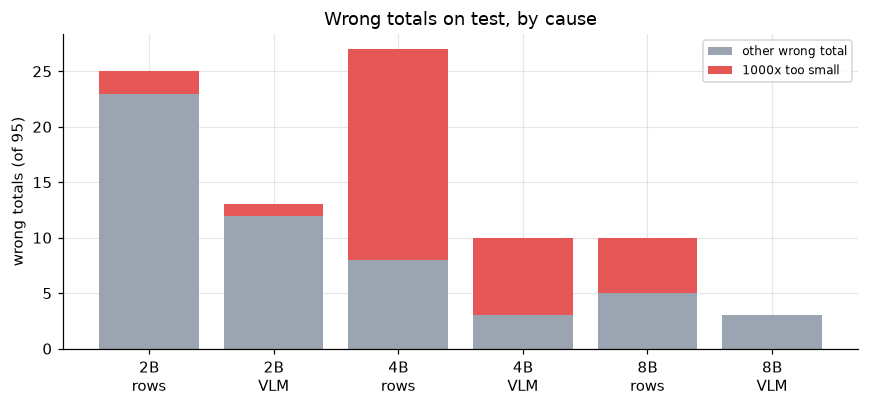

In [7]:
gt_test = {r["id"]: r["receipt"] for r in map(json.loads, open(ROOT / "data" / "processed" / "test.jsonl",
                                                              encoding="utf-8"))}


def wrong_totals(method, size):
    wrong = scaled = 0
    for o in map(json.loads, open(RUNS / f"{method}__Qwen_Qwen3-VL-{size}-Instruct__test.jsonl", encoding="utf-8")):
        t, p = gt_test[o["receipt_id"]]["total"], (o["receipt"] or {}).get("total")
        if t is None or _same("total", p, t):
            continue
        wrong += 1
        scaled += isinstance(p, (int, float)) and abs(p * 1000 - t) < 0.5
    return wrong - scaled, scaled


fig, ax = plt.subplots(figsize=(8, 3.8))
labels, other, k1000 = [], [], []
for s in SIZES:
    for m in ["ocr_llm_rows", "vlm"]:
        a, b = wrong_totals(m, s)
        labels.append(f"{s}\n{'rows' if m != 'vlm' else 'VLM'}")
        other.append(a)
        k1000.append(b)
ax.bar(labels, other, color="#9aa5b1", label="other wrong total")
ax.bar(labels, k1000, bottom=other, color="#e45756", label="1000x too small")
ax.set_ylabel("wrong totals (of 95)")
ax.set_title("Wrong totals on test, by cause")
ax.legend(fontsize=8)
save(fig, "6_wrong_totals_1000x")